# Promotional Reach and Sales Analysis

#### By Group 5: Hart Williams, Noah Torlop, Riley Lamport, Brian Arthur

**(1) Introduction**

While much of a retail grocery’s sales comes from customers’ regular purchases, promotional efforts can encourage customers to purchase additional or different products through discounts, coupons, and in-store and online promotions. Therefore, it is useful to understand what proportion of sales and shopping trips are associated with these promotional efforts, as well as what types of products are most frequently purchased through each approach. For the Regork CEO, the key business problem is determining which promotional approaches are associated with meaningful customer activity and sales and where promotional resources could be used more efficiently.

This analysis uses the Complete Journey retail dataset to assess the reach and sales associated with each promotional approach. First, over the 53 weeks in the dataset, we will determine what percentage of sales comes from items with retail discounts, items purchased with coupons, and promoted items. Additionally, we will calculate what proportion of shopping trips include these types of items, allowing us to compare their contribution to revenue with their frequency across trips. Lastly, we will examine the top types of products sold within each promotional approach.

The proposed solution is to use these results to make Regork’s promotional strategy more targeted. Rather than applying promotional efforts broadly, Regork can prioritize approaches and products that are most strongly associated with sales and customer activity. For example, if coupons account for a relatively small share of sales and shopping trips compared with other approaches, Regork may have reason to focus more resources elsewhere. Conversely, approaches associated with greater sales or broader customer activity may warrant greater attention. Overall, the findings can help Regork better align each promotional approach with the products and customer activity with which it is most strongly associated.

**(2) Packages/Libraries**

| Package | Purpose |
|---|---|
| `pandas`, `numpy` | Data manipulation, joins, and aggregation |
| `matplotlib`, `seaborn` | Charts. Seaborn draws the bar charts, and matplotlib handles formatting and annotation. |
| `warnings` | Suppresses library warnings so the report output stays clean |
| **`completejourney_py`** | Not a standard package. It provides the Complete Journey retail data (one year of transactions from 2,469 households) as pandas DataFrames through `get_data()`. |

**(3) Data Preparation**

In [1]:
!pip install completejourney-py

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from completejourney_py import get_data
cj_data = get_data()

# Tables used
transactions       = cj_data['transactions']
products           = cj_data['products']
promotions = cj_data["promotions"]

In [3]:
# Verify data shape and values not missing

transactions.info()       # About 1.5 million transaction records, no missing values
products.info()           # About 92,000 unique products, no missing values
promotions.info()         # Nearly 21 million promotions records, no missing values

# During initial data exploration, found 12,000 rows in promotions with same product id, store id, and week,
# but multiple display or mailer locations.
# Decided to treat these as duplicates and ignore them.
keys = ['week', 'store_id', 'product_id']
print("Number of promotions with same store/product/week but multiple display or mailer locations:")
promotions.duplicated(keys).sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1469307 entries, 0 to 1469306
Data columns (total 11 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   household_id           1469307 non-null  int64         
 1   store_id               1469307 non-null  int64         
 2   basket_id              1469307 non-null  int64         
 3   product_id             1469307 non-null  int64         
 4   quantity               1469307 non-null  int64         
 5   sales_value            1469307 non-null  float64       
 6   retail_disc            1469307 non-null  float64       
 7   coupon_disc            1469307 non-null  float64       
 8   coupon_match_disc      1469307 non-null  float64       
 9   week                   1469307 non-null  int64         
 10  transaction_timestamp  1469307 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(4), int64(6)
memory usage: 123.3 MB
<class 'pandas.core.fra

np.int64(12785)

**(4) Exploratory Data Analysis**

In [4]:
# What proportion of sales each week involved retail and coupon discounts, respectively

t = transactions.assign(
    retail_sales=transactions['sales_value'].where(transactions['retail_disc'] != 0, 0),
    coupon_sales=transactions['sales_value'].where(transactions['coupon_disc'] != 0, 0),
)

weekly = t.groupby('week').agg(
    retail_sales=('retail_sales', 'sum'),
    coupon_sales=('coupon_sales', 'sum'),
    sales=('sales_value', 'sum')
).reset_index()

weekly['pct_retail_sales'] = weekly['retail_sales'] / weekly['sales']
weekly['pct_coupon_sales'] = weekly['coupon_sales'] / weekly['sales']

weekly.head(10)

,week,retail_sales,coupon_sales,sales,pct_retail_sales,pct_coupon_sales
0,1,5294.81,84.42,10477.50,0.505351,0.008057
1,2,44192.76,1203.43,93370.29,0.473306,0.012889
2,3,40092.33,1103.79,83953.87,0.477552,0.013148
3,4,41622.17,1191.45,83093.82,0.500906,0.014339
4,5,40553.02,1439.11,79682.33,0.508934,0.018061
5,6,42396.35,1487.03,95878.08,0.442190,0.015510
6,7,41491.97,1293.60,89835.46,0.461866,0.014400
7,8,36795.99,960.25,80300.28,0.458230,0.011958
8,9,42749.75,1266.08,85805.50,0.498217,0.014755
9,10,45344.27,1265.47,90219.68,0.502598,0.014027


In [5]:
# Week 1 seems to be the partial week, so drop it before computing averages
weekly_trim = weekly[weekly['week'] != 1]

# Average of weekly percentages (each week counts equally)
weekly_trim[['pct_retail_sales', 'pct_coupon_sales']].mean()


,0
pct_retail_sales,0.507050
pct_coupon_sales,0.016835


In [6]:
# Pooled averages (high-volume weeks count more)
pooled_retail = weekly_trim['retail_sales'].sum() / weekly_trim['sales'].sum()
pooled_coupon = weekly_trim['coupon_sales'].sum() / weekly_trim['sales'].sum()

# Share of all sales that came from the discounted rows
print(f"% Retail Sales: {round(pooled_retail*100, 2)}, % Coupon Sales: {round(pooled_coupon*100, 2)}")

% Retail Sales: 50.71, % Coupon Sales: 1.68


In [7]:
# What proportion of shopping trips involved retail and coupon discounts, respectively

t = transactions.assign(
    has_retail=transactions['retail_disc'] != 0,
    has_coupon=transactions['coupon_disc'] != 0,
)

min_items = 3  # Exclude tiny baskets (e.g. the "one extra item" return visit)
k = 3          # Minimum discounted items for a trip to count as "retail discounted"

# One row per basket (a "trip")
trips = t.groupby('basket_id').agg(
    week=('week', 'first'),
    n_items=('sales_value', 'size'),
    n_retail=('has_retail', 'sum'),
    has_coupon=('has_coupon', 'any'),
).reset_index()

# Apply minItems and k
trips = trips[trips['n_items'] >= min_items]
trips['retail_trip'] = trips['n_retail'] >= k

# Compute weekly values
weekly_trips = trips.groupby('week').agg(
    pct_retail_trips=('retail_trip', 'mean'),
    pct_coupon_trips=('has_coupon', 'mean'),
    n_trips=('retail_trip', 'size'),
).reset_index()

# Exclude the first partial week
weekly_trips = weekly_trips[weekly_trips['week'] != 1]
weekly_trips.head(10)

,week,pct_retail_trips,pct_coupon_trips,n_trips
1,2,0.679636,0.079838,1979
2,3,0.640420,0.071916,1905
3,4,0.678642,0.077756,2032
4,5,0.645299,0.082799,1872
5,6,0.638771,0.083688,2115
6,7,0.652792,0.078680,1970
7,8,0.605744,0.065274,1915
8,9,0.690918,0.076267,1993
9,10,0.672024,0.081868,1991
10,11,0.684973,0.095357,2003


In [8]:
weekly_trips[['pct_retail_trips', 'pct_coupon_trips']].mean()
# Percent retail trips is 67.5% at k=3, at k=5 it is 45-50%

,0
pct_retail_trips,0.675363
pct_coupon_trips,0.090071


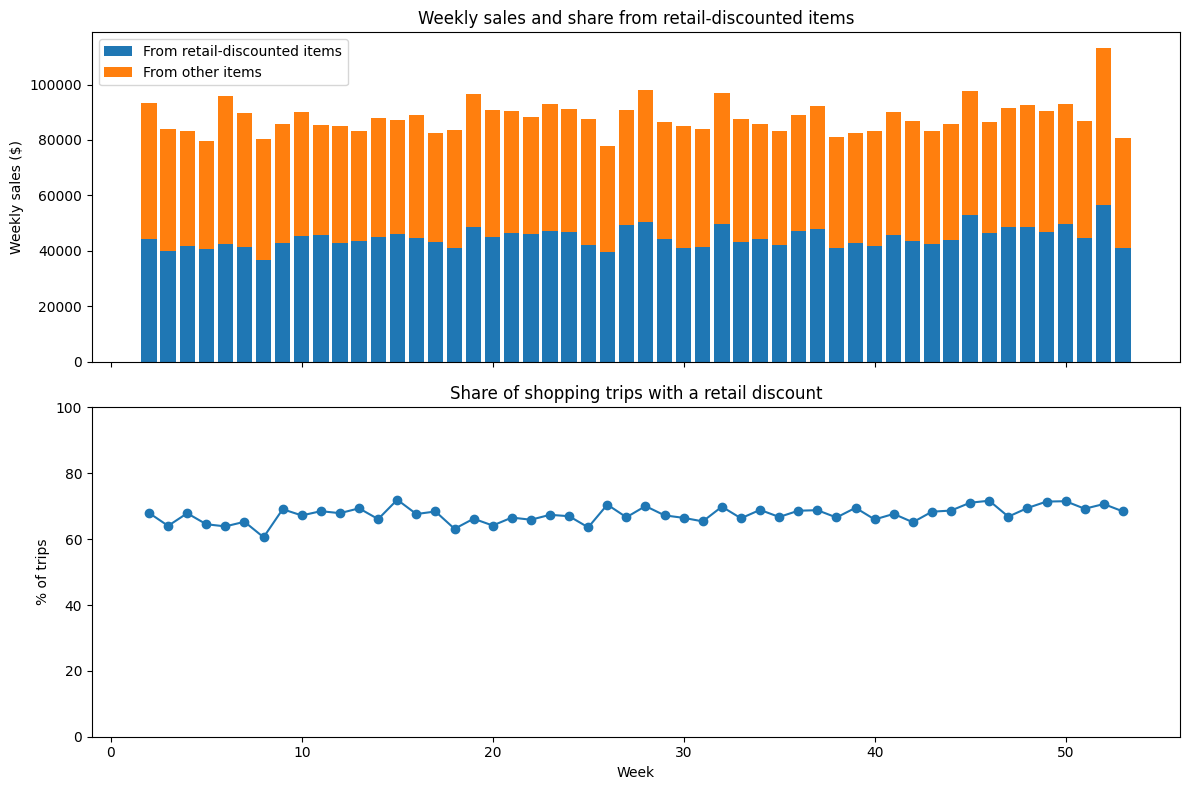

In [9]:
# Graphs for retail discount

plot_df = weekly.merge(weekly_trips[['week', 'pct_retail_trips']], on='week')
plot_df = plot_df[plot_df['week'] != 1]
plot_df['other_sales'] = plot_df['sales'] - plot_df['retail_sales']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Top: weekly sales, split into retail-discounted vs. not
ax1.bar(plot_df['week'], plot_df['retail_sales'], label='From retail-discounted items')
ax1.bar(plot_df['week'], plot_df['other_sales'], bottom=plot_df['retail_sales'],
        label='From other items')
ax1.set_ylabel('Weekly sales ($)')
ax1.set_title('Weekly sales and share from retail-discounted items')
ax1.legend()

# Bottom: share of trips with a retail discount
ax2.plot(plot_df['week'], plot_df['pct_retail_trips'] * 100, marker='o')
ax2.set_ylabel('% of trips')
ax2.set_xlabel('Week')
ax2.set_title('Share of shopping trips with a retail discount')
ax2.set_ylim(0, 100)

plt.tight_layout()
plt.show()

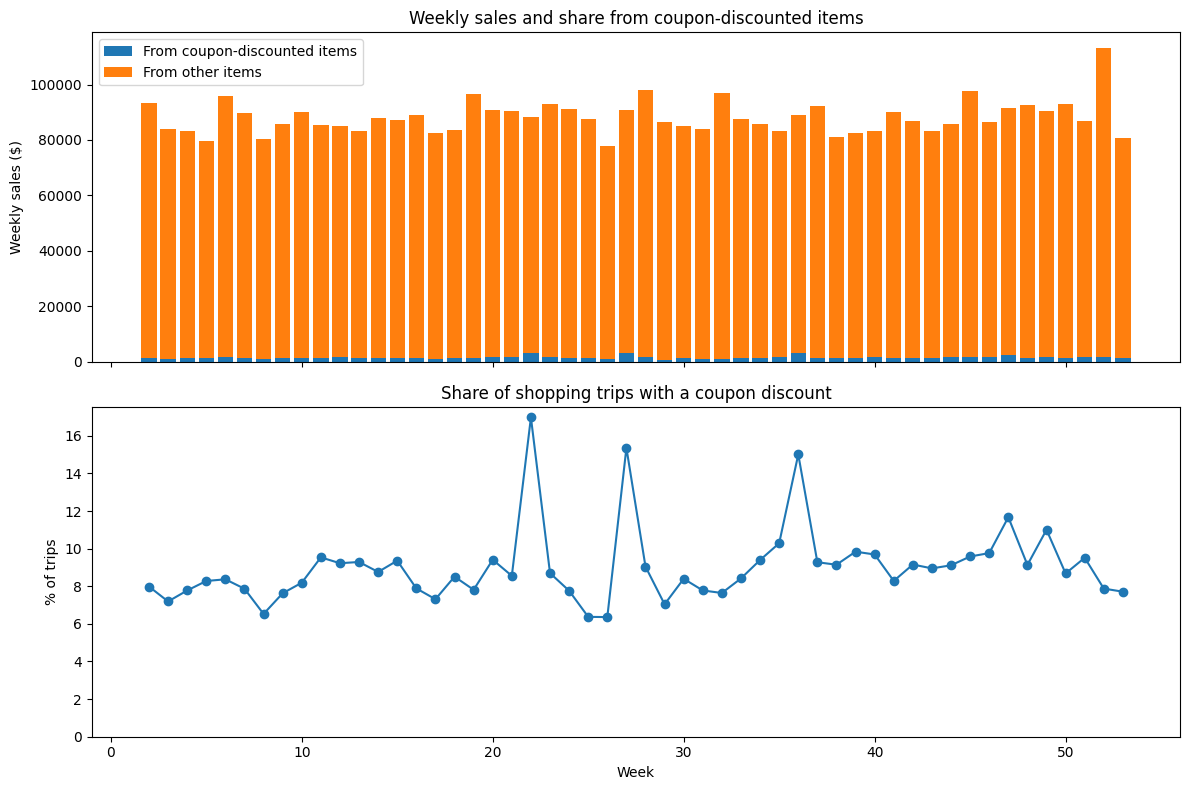

In [10]:
# Graphs for coupon discount

plot_df = weekly.merge(weekly_trips[['week', 'pct_coupon_trips']], on='week')
plot_df = plot_df[plot_df['week'] != 1]
plot_df['other_sales'] = plot_df['sales'] - plot_df['coupon_sales']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Top: weekly sales, split into coupon-discounted vs. not
ax1.bar(plot_df['week'], plot_df['coupon_sales'], label='From coupon-discounted items')
ax1.bar(plot_df['week'], plot_df['other_sales'], bottom=plot_df['coupon_sales'],
        label='From other items')
ax1.set_ylabel('Weekly sales ($)')
ax1.set_title('Weekly sales and share from coupon-discounted items')
ax1.legend()

# Bottom: share of trips with a coupon
ax2.plot(plot_df['week'], plot_df['pct_coupon_trips'] * 100, marker='o')
ax2.set_ylabel('% of trips')
ax2.set_xlabel('Week')
ax2.set_title('Share of shopping trips with a coupon discount')
ax2.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

In [11]:
# What proportion of sales and shopping trips come from promoted items

keys = ['week', 'store_id', 'product_id']

# Promoted product-store-weeks (one row per key)
promo_keys = (
    promotions[(promotions['display_location'].astype(str) != '0') |
               (promotions['mailer_location'].astype(str) != '0')]
    [keys].drop_duplicates()
)

t = transactions.merge(promo_keys, on=keys, how='left', indicator='m')
t['promoted'] = t['m'] == 'both'
t['promo_sales'] = t['sales_value'].where(t['promoted'], 0)

# Weekly share of sales from promoted items
weekly_sales = t.groupby('week').agg(
    promo_sales=('promo_sales', 'sum'),
    sales=('sales_value', 'sum'),
).reset_index()
weekly_sales['pct_promo_sales'] = weekly_sales['promo_sales'] / weekly_sales['sales']

# Weekly share of trips with at least one promoted item
min_items = 3
trips = t.groupby('basket_id').agg(
    week=('week', 'first'),
    n_items=('sales_value', 'size'),
    has_promo=('promoted', 'any'),
).reset_index()
trips = trips[trips['n_items'] >= min_items]

weekly_trips = trips.groupby('week').agg(
    pct_promo_trips=('has_promo', 'mean'),
    n_trips=('has_promo', 'size'),
).reset_index()

weekly_promo = weekly_sales.merge(weekly_trips, on='week')
weekly_promo = weekly_promo[weekly_promo['week'] != 1]

In [12]:
weekly_promo.head(10)

,week,promo_sales,sales,pct_promo_sales,pct_promo_trips,n_trips
1,2,17334.05,93370.29,0.185648,0.745831,1979
2,3,15544.19,83953.87,0.185152,0.731234,1905
3,4,16060.81,83093.82,0.193285,0.757382,2032
4,5,16166.16,79682.33,0.202883,0.734509,1872
5,6,21057.85,95878.08,0.219632,0.762648,2115
6,7,17294.56,89835.46,0.192514,0.754822,1970
7,8,14221.96,80300.28,0.177110,0.682507,1915
8,9,16576.93,85805.50,0.193192,0.780231,1993
9,10,18867.92,90219.68,0.209133,0.741838,1991
10,11,17247.74,85529.53,0.201658,0.760859,2003


In [13]:
print("Average weekly percent of sales from promoted items:")
weekly_promo[['pct_promo_sales']].mean() # Each week counts eqully

Average weekly percent of sales from promoted items:


,0
pct_promo_sales,0.196244


In [14]:
# Pooled averages (high-volume weeks count more)
pooled_prom = weekly_promo['promo_sales'].sum() / weekly_promo['sales'].sum()
print(f"% Promoted Sales: {round(pooled_prom*100, 2)}")

% Promoted Sales: 19.68


In [15]:
print("Average weekly percent of trips involving a promoted item:")
weekly_promo[['pct_promo_trips']].mean()

Average weekly percent of trips involving a promoted item:


,0
pct_promo_trips,0.752219


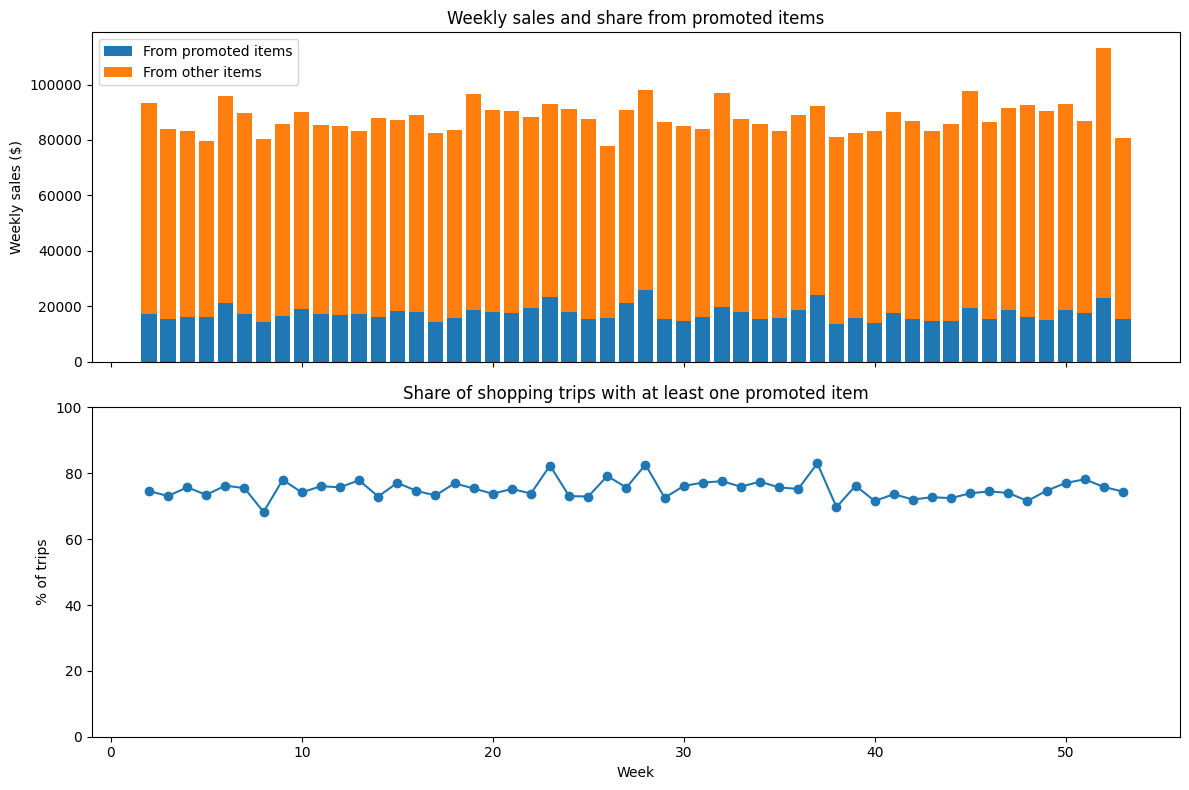

In [16]:
# Graphs for promoted items

plot_df = weekly_promo.copy()
plot_df['other_sales'] = plot_df['sales'] - plot_df['promo_sales']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Top: weekly sales, split into promoted vs. not
ax1.bar(plot_df['week'], plot_df['promo_sales'], label='From promoted items')
ax1.bar(plot_df['week'], plot_df['other_sales'], bottom=plot_df['promo_sales'],
        label='From other items')
ax1.set_ylabel('Weekly sales ($)')
ax1.set_title('Weekly sales and share from promoted items')
ax1.legend()

# Bottom: share of trips with at least one promoted item
ax2.plot(plot_df['week'], plot_df['pct_promo_trips'] * 100, marker='o')
ax2.set_ylabel('% of trips')
ax2.set_xlabel('Week')
ax2.set_title('Share of shopping trips with at least one promoted item')
ax2.set_ylim(0, 100)

plt.tight_layout()
plt.show()

In [17]:
# Top 10 products sold with a retail discount and coupon discount, respectively
# By total revenue

# Reusable function
def top_discounted(disc_col, n=10):
    return (
        transactions[transactions[disc_col] != 0]
        .groupby('product_id')['sales_value']
        .agg(n_discounted='size', disc_sales='sum')
        .sort_values('disc_sales', ascending=False)
        .head(n)
        .reset_index()
        .merge(products[['product_id', 'product_type']].drop_duplicates('product_id'),
               on='product_id', how='left')
    )

top_retail = top_discounted('retail_disc')
top_coupon = top_discounted('coupon_disc')

In [18]:
top_retail

,product_id,n_discounted,disc_sales,product_type
0,6534178,11581,303101.02,GASOLINE-REG UNLEADED
1,6533889,823,27467.61,GASOLINE-REG UNLEADED
2,6534166,722,20477.54,GASOLINE-REG UNLEADED
3,916122,2462,15810.86,CHICKEN BREAST BONELESS
4,995242,6157,13072.40,FLUID MILK WHITE ONLY
5,5569230,2636,12730.79,SOFT DRINKS 12/18&15PK CAN CAR
6,844179,1677,8315.80,PRIMAL
7,1044078,1715,7630.65,LEAN
8,1133018,3604,7193.62,FLUID MILK WHITE ONLY
9,5569471,1214,6901.54,SOFT DRINKS 12/18&15PK CAN CAR


In [19]:
top_coupon

,product_id,n_discounted,disc_sales,product_type
0,5569230,164,1655.61,SOFT DRINKS 12/18&15PK CAN CAR
1,1775642,22,1322.74,CIGARETTES
2,979674,30,1075.20,CIGARETTES
3,5569471,91,1013.26,SOFT DRINKS 12/18&15PK CAN CAR
4,5569374,46,497.13,SOFT DRINKS 12/18&15PK CAN CAR
5,1087618,17,470.42,CIGARETTES
6,1052294,13,452.97,CIGARETTES
7,5569845,46,405.07,SOFT DRINKS 12/18&15PK CAN CAR
8,6978899,10,404.36,VITAMIN - NON HERBAL SUPPLEMEN
9,8090537,46,392.09,SOFT DRINKS 12/18&15PK CAN CAR


In [20]:
# Top promoted items sold
top_promoted = (
    t[t['promoted']]
    .groupby('product_id')['sales_value']
    .agg(n_promoted='size', promo_sales='sum')
    .sort_values('promo_sales', ascending=False)
    .head(10)
    .reset_index()
    .merge(products[['product_id', 'product_type']].drop_duplicates('product_id'),
           on='product_id', how='left')
)
top_promoted

,product_id,n_promoted,promo_sales,product_type
0,995242,4970,10960.67,FLUID MILK WHITE ONLY
1,916122,1736,10609.11,CHICKEN BREAST BONELESS
2,5569230,1960,9794.91,SOFT DRINKS 12/18&15PK CAN CAR
3,1029743,3143,8663.30,FLUID MILK WHITE ONLY
4,1044078,1437,6468.67,LEAN
5,1133018,2886,5925.16,FLUID MILK WHITE ONLY
6,1106523,2096,5746.98,FLUID MILK WHITE ONLY
7,5569471,926,5612.86,SOFT DRINKS 12/18&15PK CAN CAR
8,844179,1123,5599.70,PRIMAL
9,874972,449,5166.36,SELECT BEEF


**(5) Summary**

Over the 53 weeks of Complete Journey data, the three promotional approaches vary greatly for Regork's promotional activities (week 1 is excluded as a partial week).


| Approach | Share of sales | Share of shopping trips |
|---|---|---|
| Retail discount | 50.7% | 67.5% (trips with at least 3 discounted items) |
| Promoted (display or mailer) | 19.7% | 75.2% (trips with at least 1 promoted item) |
| Coupon | 1.7% | 9.0% (trips with at least 1 coupon item) |


**Retail discounts** are the most significant approach. About half of all sales involve a retail discount, and roughly two-thirds of trips include several discounted items. Both measures are stable from week to week, so retail discounts function as a consistent feature of Regork's pricing rather than a periodic campaign. Gasoline is by far the largest discounted product, followed by chicken breast, white milk, and soft drinks.

**Promoted items** account for about 20% of sales but appear in roughly three out of four shopping trips. These placements therefore reach nearly every shopper while carrying a smaller share of revenue. The top promoted products are everyday staples: white milk, chicken breast, soft drinks, and beef.

**Coupons** have the smallest footprint, at under 2% of sales and about 9% of trips. Coupon use rose to roughly 15 to 17% of trips in weeks 22, 27, and 36, but total weekly sales in those weeks did not visibly change. These spikes occured around federal holidays that landed on those weeks. Coupon-related sales are concentrated in a few product types, mainly soft drinks, cigarettes, and vitamins, at small dollar amounts.

**Recommendation:** Regork should concentrate its promotional resources on retail discounts and display or mailer placements for high-volume staples such as milk, chicken, and soft drinks, which reach the most customers and carry the most revenue. Coupons should be treated as a targeted tool rather than a broad program, and the spike weeks should be reviewed to understand what drove the increase in coupon use (like major holidays, season changes, or culture moments taking place) before similar efforts are repeated.

**Limitations:** These results show association, not causation. We did not measure whether promotions increase sales beyond what would have occurred anyway, so the coupon findings describe current reach, not effectiveness. Trip shares also depend on how a trip is defined: retail trips require at least 3 discounted items, and the share falls to about 45–50% at 5 items, while coupon and promoted trips require only one qualifying item. The data covers 2,469 households, so results may not generalize to all Regork customers. A controlled test of coupon and promotion lift is a logical next step.